# Práctica clase 7 — Series temporales modernas: Prophet y Chronos-2

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

Contenido:
1. A mano: pronóstico aditivo por tramos y MASE
2. Prophet sobre las visitas mensuales simuladas
3. Chronos-2 y la tabla de MASE
4. La decisión

In [1]:
# Celda de instalación: correrla apenas se abre el notebook.
# Si Colab pide reiniciar la sesión, reiniciar y seguir con la celda de datos.
!pip install -q prophet chronos-forecasting statsforecast

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
elementary-data 0.23.1 requires networkx<3,>=2.3, but you have networkx 3.6.1 which is incompatible.
fastapi 0.104.1 requires anyio<4.0.0,>=3.7.1, but you have anyio 4.15.1 which is incompatible.
sqlfluff 4.1.0 requires click<8.4.0, but you have click 8.5.0 which is incompatible.

[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## Parte 1: A mano

Visitas trimestrales (en miles) de un parque durante dos años, $t = 1,\dots,8$:

| $t$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| Trimestre | T1 | T2 | T3 | T4 | T1 | T2 | T3 | T4 |
| Visitas | 26 | 24 | 19 | 21 | 29 | 28 | 22 | 25 |

Modelo aditivo tipo Prophet, con una campaña de promoción que arranca en $t=8$:

$$g(t)=\begin{cases}20+t & t\le 8\\ 28+3(t-8) & t>8\end{cases}\qquad
s(t):\ \text{T1 } +5,\ \text{T2 } +2,\ \text{T3 } -4,\ \text{T4 } -3$$

### 1.1 Calcular $g(t)$, $s(t)$ y $\hat y(t)=g(t)+s(t)$ para $t=9,10,11,12$

Todos son $t>8$, así que se usa el segundo tramo de $g$. El trimestre de $t$ es T1 para $t=9$, T2 para $t=10$, T3 para $t=11$ y T4 para $t=12$.

| $t$ | Trimestre | $g(t)$ | $s(t)$ | $\hat y(t)=g+s$ |
|---|---|---|---|---|
| 9 | T1 | $28+3(1)=31$ | $+5$ | **36** |
| 10 | T2 | $28+3(2)=34$ | $+2$ | **36** |
| 11 | T3 | $28+3(3)=37$ | $-4$ | **33** |
| 12 | T4 | $28+3(4)=40$ | $-3$ | **37** |

### 1.2 Ingenuo estacional

Cada trimestre repite el del año anterior, $\hat y_t = y_{t-4}$, así que para $t=9,\dots,12$ pronostica $y_5,\dots,y_8$:

$$\hat y^{\text{ingenuo}} = 29,\ 28,\ 22,\ 25.$$

### 1.3 Escala del MASE

Error absoluto medio del ingenuo estacional dentro del entrenamiento:

$$\text{escala}=\frac14\sum_{t=5}^{8}|y_t-y_{t-4}|=\frac{|29-26|+|28-24|+|22-19|+|25-21|}{4}=\frac{3+4+3+4}{4}=3.5$$

### 1.4 MASE del modelo aditivo y del ingenuo

Valores reales: $35, 37, 31, 38$.

- **Modelo aditivo:** errores $|35-36|, |37-36|, |31-33|, |38-37| = 1, 1, 2, 1$. Media $=1.25$, así que $\text{MASE}=1.25/3.5\approx \mathbf{0.357}$.
- **Ingenuo:** errores $|35-29|, |37-28|, |31-22|, |38-25| = 6, 9, 9, 13$. Media $=9.25$, así que $\text{MASE}=9.25/3.5\approx \mathbf{2.643}$.

### 1.5 ¿Por qué al ingenuo le va tan mal aquí?

El ingenuo estacional copia el año anterior y asume que el nivel no cambió. Pero la campaña hizo que la tendencia **acelerara** desde $t=8$ (la pendiente pasa de $1$ a $3$ miles por trimestre), así que cada trimestre del 2.º año queda cada vez más por encima del equivalente del 1.er año, y el error crece con el horizonte (6, 9, 9, 13). El modelo por tramos sí conoce el cambio de pendiente.

Un MASE de 2.64 significa que el ingenuo se equivoca 2.64 veces lo que se equivoca, en promedio, el propio ingenuo dentro del entrenamiento.

In [2]:
# Verificación en código de la parte 1 (los números de arriba salen a mano).
import numpy as np

y = np.array([26, 24, 19, 21, 29, 28, 22, 25])      # visitas t = 1..8
real = np.array([35, 37, 31, 38])                   # valores reales de t = 9..12

t_fut = np.arange(9, 13)
g = 28 + 3 * (t_fut - 8)                            # tendencia del 2.º tramo (t > 8)
s = np.array([5, 2, -4, -3])                        # efecto estacional T1..T4
y_modelo = g + s
y_ingenuo = y[4:]                                   # repite el año anterior (y_5..y_8)

escala = np.mean(np.abs(y[4:] - y[:4]))             # error del ingenuo dentro del entrenamiento

print("g(t):", g, "| yhat:", y_modelo, "| ingenuo:", y_ingenuo)
print("escala:", escala)
print("MASE modelo aditivo:", round(np.mean(np.abs(real - y_modelo)) / escala, 3))
print("MASE ingenuo:       ", round(np.mean(np.abs(real - y_ingenuo)) / escala, 3))

g(t): [31 34 37 40] | yhat: [36 36 33 37] | ingenuo: [29 28 22 25]
escala: 3.5
MASE modelo aditivo: 0.357
MASE ingenuo:        2.643


---
## Parte 2: Prophet

Visitas mensuales simuladas a un parque nacional, 2017 a 2024: temporada alta en la época seca y una tendencia que pasa de crecer 150 visitas por mes a 400 desde 2022. Se entrena hasta 2023 y 2024 queda como prueba.

### 2.1 Datos y gráfico de la serie

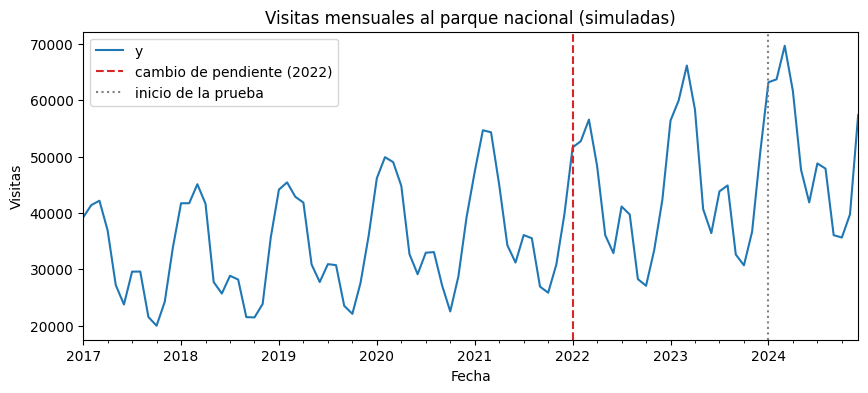

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)                       # semilla 7: los números deben coincidir con el enunciado
n = 96                                               # 8 años x 12 meses
t = np.arange(1, n + 1)

# tendencia por tramos: crece más rápido desde 2022 (t = 61)
tendencia = np.where(t <= 60, 30000 + 150 * t, 39000 + 400 * (t - 60))

# factor estacional multiplicativo por mes (ene..dic): alto en la época seca, bajo en la lluviosa
patron = np.array([1.30, 1.35, 1.40, 1.25, 0.90, 0.80,
                   0.95, 0.90, 0.70, 0.65, 0.75, 1.05])

ruido = rng.normal(0, 0.04, n)                       # ruido multiplicativo de ~4 %
visitas = np.round(tendencia * patron[(t - 1) % 12] * (1 + ruido))

df = pd.DataFrame({"ds": pd.date_range("2017-01-01", periods=n, freq="MS"),
                   "y": visitas})
train = df[df.ds < "2024-01-01"]                     # 84 meses (2017-2023)
test = df[df.ds >= "2024-01-01"]                     # 12 meses (2024)

ax = df.plot(x="ds", y="y", figsize=(10, 4), legend=False)
ax.axvline(pd.Timestamp("2022-01-01"), color="tab:red", ls="--", label="cambio de pendiente (2022)")
ax.axvline(pd.Timestamp("2024-01-01"), color="gray", ls=":", label="inicio de la prueba")
ax.set(title="Visitas mensuales al parque nacional (simuladas)", xlabel="Fecha", ylabel="Visitas")
ax.legend()
plt.show()

**Lectura del gráfico:** se ve la estacionalidad anual (picos a comienzos de año, valles hacia el segundo semestre) y, sobre todo, que la serie sube más rápido a partir de 2022: la pendiente de la tendencia cambia y, como la estacionalidad es multiplicativa, la **amplitud** de las oscilaciones también crece con el nivel. Por eso conviene `seasonality_mode="multiplicative"`.

### 2.2 Ajustar Prophet con estacionalidad multiplicativa y pronosticar 12 meses

18:00:04 - cmdstanpy - INFO - Chain [1] start processing
18:00:04 - cmdstanpy - INFO - Chain [1] done processing


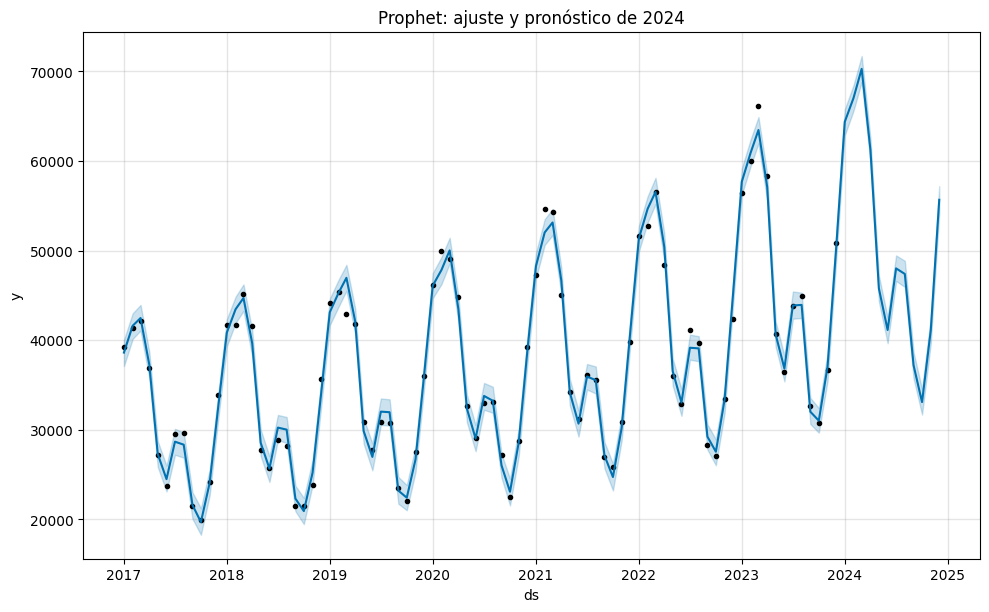

In [4]:
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)   # silencia los mensajes de Stan
from prophet import Prophet

# yearly_seasonality: patrón anual; "multiplicative": la estacionalidad escala con el nivel de la serie
m = Prophet(yearly_seasonality=True, seasonality_mode="multiplicative")
m.fit(train)

futuro = m.make_future_dataframe(periods=12, freq="MS")    # 84 meses de train + 12 de 2024
fcst = m.predict(futuro)                                    # yhat, trend, yearly, bandas de incertidumbre

m.plot(fcst)
plt.title("Prophet: ajuste y pronóstico de 2024")
plt.show()

### 2.3 Componentes: mes más alto y más bajo

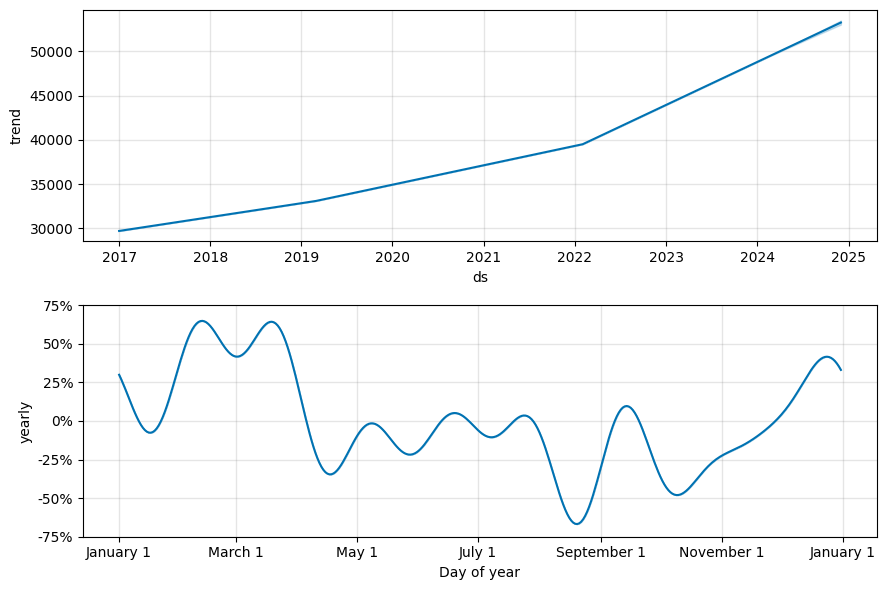

      mes  efecto_%
  January      31.3
 February      37.3
    March      41.9
    April      26.5
      May     -10.8
     June     -19.9
     July      -5.4
   August      -6.1
September     -32.2
  October     -34.8
 November     -22.8
 December       3.4

Mes más alto: March (+41.9%)
Mes más bajo: October (-34.8%)


In [5]:
m.plot_components(fcst)
plt.show()

# El mismo resultado en números: efecto estacional anual (fracción de la tendencia) en los 12 meses de 2023
est = fcst.loc[fcst.ds.dt.year == 2023, ["ds", "yearly"]].copy()
est["mes"] = est.ds.dt.month_name()
est["efecto_%"] = (est.yearly * 100).round(1)
print(est[["mes", "efecto_%"]].to_string(index=False))
print("\nMes más alto:", est.loc[est.yearly.idxmax(), "mes"], f"({est.yearly.max():+.1%})")
print("Mes más bajo:", est.loc[est.yearly.idxmin(), "mes"], f"({est.yearly.min():+.1%})")

**Resultado:** el pico anual está en **marzo** (cerca de +42 % sobre la tendencia) y el valle en **octubre** (cerca de −35 %).

**¿Coincide con la temporada seca y la lluviosa?** Sí. En Costa Rica la época seca va de diciembre a abril: la serie sube desde diciembre, alcanza el máximo en marzo y cae en mayo. La época lluviosa va de mayo a noviembre, con los mínimos en septiembre y octubre, los meses más lluviosos del año. Además es coherente con el `patron` usado para simular los datos (máximo en marzo, 1.40; mínimo en octubre, 0.65), así que Prophet recuperó la estacionalidad correcta.

### 2.4 Pendiente de la tendencia antes y después de 2022

In [6]:
tr = fcst.trend.values                               # tendencia estimada (84 meses de train + 12 de pronóstico)

# diff = aumento de la tendencia de un mes al siguiente; su promedio es la pendiente (visitas por mes)
print("pendiente 2017-2021:", np.diff(tr[:60]).mean().round(1))      # meses 1..60  (verdad: 150)
print("pendiente 2022-2023:", np.diff(tr[60:84]).mean().round(1))    # meses 61..84 (verdad: 400)
# referencia del enunciado: 159.8 y 394.1

pendiente 2017-2021: 159.8
pendiente 2022-2023: 394.1


**¿Recuperó Prophet el 150 y el 400?** Sí, casi: estimó ~160 por mes antes de 2022 y ~394 después, contra 150 y 400 reales. Nadie le indicó dónde estaba el quiebre: Prophet coloca por sí mismo *changepoints* candidatos en el primer 80 % de la serie y una penalización decide cuáles usar, y así encontró el cambio de 2022.

---
## Parte 3: Chronos-2 y la tabla de MASE

### 3.1 Chronos-2 sin entrenar (zero-shot)

La primera vez descarga los pesos desde Hugging Face (unos cientos de MB). Funciona en CPU; con GPU (Entorno de ejecución → Cambiar tipo de entorno) se puede usar `device_map="cuda"`.

In [11]:
from chronos import Chronos2Pipeline

# modelo preentrenado: no se entrena con esta serie, solo la usa como contexto
pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")

# solo train como contexto; el formato largo exige las columnas id / timestamp / target
contexto = train.assign(id="parque").rename(columns={"ds": "timestamp", "y": "target"})

pred = pipeline.predict_df(contexto, prediction_length=12,
                           quantile_levels=[0.1, 0.5, 0.9],        # banda 10-90 % y mediana
                           id_column="id", timestamp_column="timestamp", target="target")
pred.head()

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

,id,timestamp,target_name,predictions,0.1,0.5,0.9
0,parque,2024-01-01,target,63084.261719,59765.828125,63084.261719,67805.804688
1,parque,2024-02-01,target,68046.984375,63634.742188,68046.984375,72509.203125
2,parque,2024-03-01,target,68797.195312,64673.929688,68797.195312,73880.890625
3,parque,2024-04-01,target,60795.542969,57472.296875,60795.542969,65233.937500
4,parque,2024-05-01,target,45865.261719,43035.058594,45865.261719,49116.414062


### 3.2 Referencias: ingenuo estacional y AutoETS

In [12]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

# AutoETS elige automáticamente error / tendencia / estacionalidad (ETS) con período 12
sf = StatsForecast(models=[AutoETS(season_length=12)], freq="MS")
ets = sf.forecast(df=train.assign(unique_id="parque"), h=12)    # statsforecast exige la columna unique_id
ets.head()

,unique_id,ds,AutoETS
0,parque,2024-01-01,60110.501209
1,parque,2024-02-01,63733.813137
2,parque,2024-03-01,65695.973735
3,parque,2024-04-01,58806.315059
4,parque,2024-05-01,42750.691845


### 3.3 MASE de los cuatro modelos

In [9]:
def mase(real, pron, entrenamiento, m=12):
    # escala = error absoluto medio del ingenuo estacional (período m) dentro del entrenamiento
    escala = np.mean(np.abs(entrenamiento[m:] - entrenamiento[:-m]))
    return np.mean(np.abs(real - pron)) / escala

y_tr, y_te = train.y.values, test.y.values

pronosticos = {"SeasonalNaive": y_tr[-12:],                 # repite 2023 como pronóstico de 2024
               "Prophet": fcst.yhat.values[-12:],           # últimos 12 meses = 2024
               "AutoETS": ets["AutoETS"].values,
               "Chronos-2": pred["0.5"].values}             # mediana del pronóstico probabilístico

tabla = pd.DataFrame({"MASE": {k: mase(y_te, v, y_tr) for k, v in pronosticos.items()}})
tabla.sort_values("MASE").round(3)
# referencia del enunciado:
# Prophet 0.479 | Chronos-2 0.486 | AutoETS 1.101 | SeasonalNaive 1.658

,MASE
Prophet,0.479
Chronos-2,0.486
AutoETS,1.101
SeasonalNaive,1.658


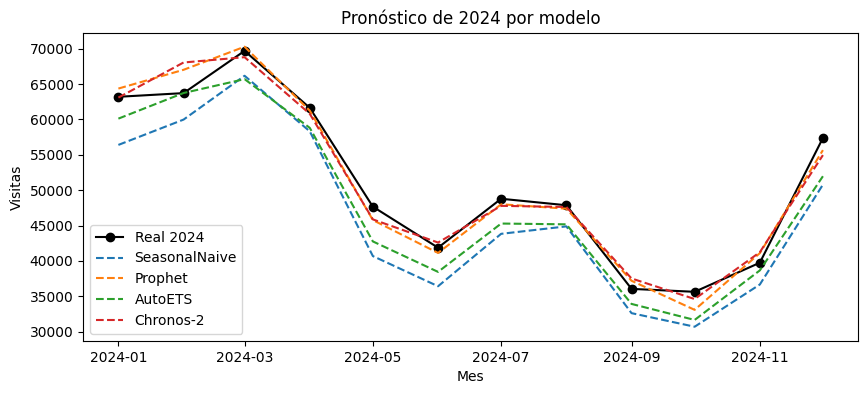

In [10]:
# Pronósticos de 2024 contra lo observado
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(test.ds, y_te, "k-o", label="Real 2024")
for nombre, v in pronosticos.items():
    ax.plot(test.ds, v, "--", label=nombre)
ax.set(title="Pronóstico de 2024 por modelo", xlabel="Mes", ylabel="Visitas")
ax.legend()
plt.show()

**Lectura de la tabla** (resultados obtenidos en la corrida, semilla 7; coinciden con los del enunciado):

| Modelo | MASE |
|---|---|
| Prophet | 0.479 |
| Chronos-2 | 0.486 |
| AutoETS | 1.101 |
| SeasonalNaive | 1.658 |

- Prophet gana por poco y Chronos-2 queda prácticamente empatado **sin haber entrenado** con esta serie.
- AutoETS y el ingenuo se quedan atrás porque el cambio de pendiente es reciente y les pesa la historia vieja. En el gráfico se ve: ambos subestiman casi todos los meses de 2024, mientras que Prophet y Chronos-2 siguen de cerca la serie real.
- Un MASE mayor que 1 compara contra el ingenuo *en el entrenamiento*, no en la prueba. Por eso AutoETS (1.10) puede tener MASE mayor que 1 y aun así ganarle al ingenuo en la prueba (1.66): 2024 es más difícil de pronosticar que los años del entrenamiento, porque la tendencia es más empinada.

**¿En qué situación esperarían que el orden se invierta?**
- **Sin quiebre de pendiente** (tendencia estable): el ingenuo y AutoETS dejarían de arrastrar la historia vieja y su MASE bajaría a ~1 o menos; Prophet perdería su ventaja.
- **Serie con dinámica de corto plazo y autocorrelación** (no solo tendencia + estacionalidad anual): AutoETS, un ARIMA o Chronos-2 pueden superar a Prophet, que solo modela tendencia, estacionalidad y feriados.
- **Quiebre dentro del período de prueba** (p. ej. una caída de pendiente en 2024 por el cierre del parque): Prophet extrapolaría la tendencia vieja y fallaría, mientras que modelos que reaccionan a los últimos datos (Chronos-2, ETS) se adaptarían más rápido.
- **Muy pocos datos o una serie muy distinta a lo que vio el preentrenamiento**: el modelo fundacional pierde ventaja y los modelos con estructura explícita (Prophet, ETS) pueden ganar; con mucha historia y patrones complejos, Chronos-2 suele ganar.

---
## Parte 4: La decisión

**La elección.** Para el pronóstico de 2025 usaríamos **Prophet**, con **Chronos-2 como modelo de contraste**.
- *Precisión:* Prophet tiene el menor MASE (0.479), pero la diferencia con Chronos-2 (0.486) es mínima: con una sola ventana de prueba no se puede afirmar que uno sea mejor que el otro. Ambos están muy por debajo de AutoETS (1.10) y del ingenuo (1.66).
- *Facilidad de explicarlo:* Prophet se descompone en tendencia + estacionalidad anual, y eso se le puede mostrar a quien decide (pico en marzo, valle en octubre, pendiente de ~394 visitas por mes). Chronos-2 es una caja negra: da un buen pronóstico pero no dice por qué.
- *Un solo año de prueba:* 12 puntos son muy poca evidencia, y el cambio de pendiente de 2022 es justo el tipo de situación en que unos modelos aciertan y otros no. Preferimos el modelo que podemos explicar y auditar, y no apostar por una diferencia de 0.007 en el MASE.

**La sospecha.** Antes de decidir haríamos una **validación con ventana expansiva** (*rolling-origin*, o `cross_validation` de Prophet): entrenar hasta un corte, pronosticar los siguientes 12 meses, avanzar el corte (p. ej. cada 6 o 12 meses) y repetir. Con varios orígenes se calcula el MASE promedio de cada modelo y su dispersión, y se ve si Prophet gana de forma consistente o solo en 2024. También revisaríamos qué pasa con cortes antes y después del cambio de 2022, y la cobertura de las bandas de 10-90 %, no solo el pronóstico central.

**El proyecto.**
- ¿Nuestro tema tiene una serie de tiempo? _(sí / no; cuál: variable, frecuencia, período)_
- Línea base: _(p. ej. ingenuo estacional o promedio móvil)_
- Modelo moderno: _(p. ej. Prophet, Chronos-2 u otro)_